In [1]:
from auxin_signalling_pathway.reduced_auxin_signalling_pathway import \
    reduced_auxin_signalling_pathway as reduced_asp_class
from auxin_signalling_pathway import auxin_signalling_pathway as asp_class

import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import sympy as sp
import seaborn as sns

In [2]:
kwargs = {'nARFs': 1, 'nIAAs': 1}

asp_model_r = reduced_asp_class(**kwargs)
asp_model_full = asp_class(**kwargs)
asp_model_full.remove_state('G__ARF_1')

In [3]:
# Find all parameters related to the promoter-protein dynamics
empty_set_node = asp_model_full.empty_set_node
aux_symbol = asp_model_full.aux_symbol

pp_reactions = []
promoter_symbols = [s for s in asp_model_full.get_state_variables() if s[0]=='G']
for r in asp_model_full._reactions_set:
    if np.all(np.isin(r.reactants + r.products, promoter_symbols)):
        pp_reactions.append(r)
    
pp_parameters = [s for r in pp_reactions for s in r.fwd_rates + r.bwd_rates]
print(asp_model_full.get_default_parameters())
print(pp_parameters)

{'arf__d': 1.0, 'arf__k': 1.0, 'd__D__ARF_1__ARF_1': 0.1, 'd__D__ARF_1__iaa_1': 0.1, 'd__D__iaa_1__iaa_1': 0.1, 'd__G__ARF_1': 0.01, 'd__G__ARF_1__ARF_1': 0.01, 'd__G__ARF_1__ARF_1__unbind__ARF_1': 0.0, 'd__G__ARF_1__iaa_1': 0.01, 'd__G__ARF_1__iaa_1__unbind__iaa_1': 0.0, 'd__R': 0.01, 'd__iaa_1_x': 0.1, 'iaa__d': 1.0, 'iaa__k': 1.0, 'k__D__ARF_1__ARF_1': 0.001, 'k__D__ARF_1__iaa_1': 0.001, 'k__D__iaa_1__iaa_1': 0.001, 'k__G__ARF_1': 0.1, 'k__G__ARF_1__ARF_1': 0.1, 'k__G__ARF_1__ARF_1__R__iaa_1': 1.0, 'k__G__ARF_1__R__iaa_1': 1.0, 'k__G__ARF_1__bind__ARF_1': 0.0, 'k__G__ARF_1__bind__iaa_1': 0.0, 'k__G__ARF_1__iaa_1': 0.1, 'k__G__ARF_1__iaa_1__R__iaa_1': 1.0, 'k__G__R__iaa_1': 1.0, 'k__R__iaa_1__iaa_1': 1.0, 'k__iaa_1': 0.0}
['k__G__ARF_1__ARF_1', 'd__G__ARF_1__ARF_1', 'k__G__ARF_1__iaa_1', 'd__G__ARF_1__iaa_1']


In [4]:
promoter_timeconstant = 'tau_G'
asp_model_full.add_transition_rate(promoter_timeconstant, 1.0, "Promoter timeconstant", strict=False)
asp_model_full.add_transition_rate("k__RNA__IAA", 1.0, "", strict=False)

full_parameter_subs_dict = asp_model_r.parameter_subs_dict.copy()
asp_model_full.remove_transition_rate('k__R__iaa_1__iaa_1')

for p in pp_parameters:
    if p in full_parameter_subs_dict:
        print(f"{full_parameter_subs_dict[p]}")
    else:
        full_parameter_subs_dict[p] = sp.sympify(p) / sp.sympify(promoter_timeconstant)

print(full_parameter_subs_dict)

{'k__R__iaa_1__iaa_1': 'k__RNA__IAA', 'k__G__ARF_1__bind__ARF_1': 0.0, 'd__G__ARF_1__ARF_1__unbind__ARF_1': 0.0, 'k__G__ARF_1__bind__iaa_1': 0.0, 'd__G__ARF_1__iaa_1__unbind__iaa_1': 0.0, 'k__G__ARF_1__iaa_1__R__iaa_1': '0.0', 'k__G__R__iaa_1': '0.0', 'k__G__ARF_1__ARF_1': k__G__ARF_1__ARF_1/tau_G, 'd__G__ARF_1__ARF_1': d__G__ARF_1__ARF_1/tau_G, 'k__G__ARF_1__iaa_1': k__G__ARF_1__iaa_1/tau_G, 'd__G__ARF_1__iaa_1': d__G__ARF_1__iaa_1/tau_G}


In [5]:
# Generate initial conditions
reduced_ic_dict = asp_model_r.get_default_initial_conditions()
full_ic_dict = asp_model_full.get_default_initial_conditions()

jac_func, inhomog_func = asp_model_r.get_promoter_ode_funcs(njitted=True)

reduced_param_dict = asp_model_r.get_default_parameters()
reduced_ic_dict = asp_model_r.get_default_initial_conditions()

full_param_dict = reduced_param_dict.copy()

odes, free_variables, transition_rates, constraints = \
    asp_model_r.generate_ode_system(reduced=True)

params = np.array(list(transition_rates.values())).astype(np.float64)

jac = jac_func(np.array(list(reduced_ic_dict.values())).astype(np.float64), 
               params,
               np.array([1.0]))

inhomog = inhomog_func(np.array(list(reduced_ic_dict.values())), 
                        params, [1.0])

initial_promoter_vars = np.linalg.solve(jac, -inhomog).flatten()
initial_promoter_vars = np.concatenate([[1.0 - initial_promoter_vars.sum()], initial_promoter_vars])

# We can set the initial conditions to be identical, but this produces less interesting plots:
#for i, p in enumerate(promoter_symbols):
#    full_ic_dict[p] = initial_promoter_vars[i]
    

{'k__R__iaa_1__iaa_1': 'k__RNA__IAA', 'k__G__ARF_1__bind__ARF_1': 0.0, 'd__G__ARF_1__ARF_1__unbind__ARF_1': 0.0, 'k__G__ARF_1__bind__iaa_1': 0.0, 'd__G__ARF_1__iaa_1__unbind__iaa_1': 0.0, 'k__G__ARF_1__iaa_1__R__iaa_1': '0.0', 'k__G__R__iaa_1': '0.0', 'k__G__ARF_1__ARF_1': k__G__ARF_1__ARF_1/tau_G, 'd__G__ARF_1__ARF_1': d__G__ARF_1__ARF_1/tau_G, 'k__G__ARF_1__iaa_1': k__G__ARF_1__iaa_1/tau_G, 'd__G__ARF_1__iaa_1': d__G__ARF_1__iaa_1/tau_G}
Matrix([[-2*ARF_1**2*k__D__ARF_1__ARF_1 - ARF_1*arf__d - ARF_1*iaa_1*k__D__ARF_1__iaa_1 + 2*D__ARF_1__ARF_1*d__D__ARF_1__ARF_1 + D__ARF_1__iaa_1*d__D__ARF_1__iaa_1 + arf__k], [ARF_1**2*k__D__ARF_1__ARF_1 - D__ARF_1__ARF_1*d__D__ARF_1__ARF_1], [ARF_1*iaa_1*k__D__ARF_1__iaa_1 - D__ARF_1__iaa_1*d__D__ARF_1__iaa_1], [-D__iaa_1__iaa_1*d__D__iaa_1__iaa_1 + iaa_1**2*k__D__iaa_1__iaa_1], [(-D__ARF_1__ARF_1*G*k__G__ARF_1__ARF_1 + D__ARF_1__ARF_1*G__ARF_1__ARF_1*d__G__ARF_1__ARF_1 - D__ARF_1__iaa_1*G*k__G__ARF_1__iaa_1 + D__ARF_1__iaa_1*G__ARF_1__iaa_1*d__G__A

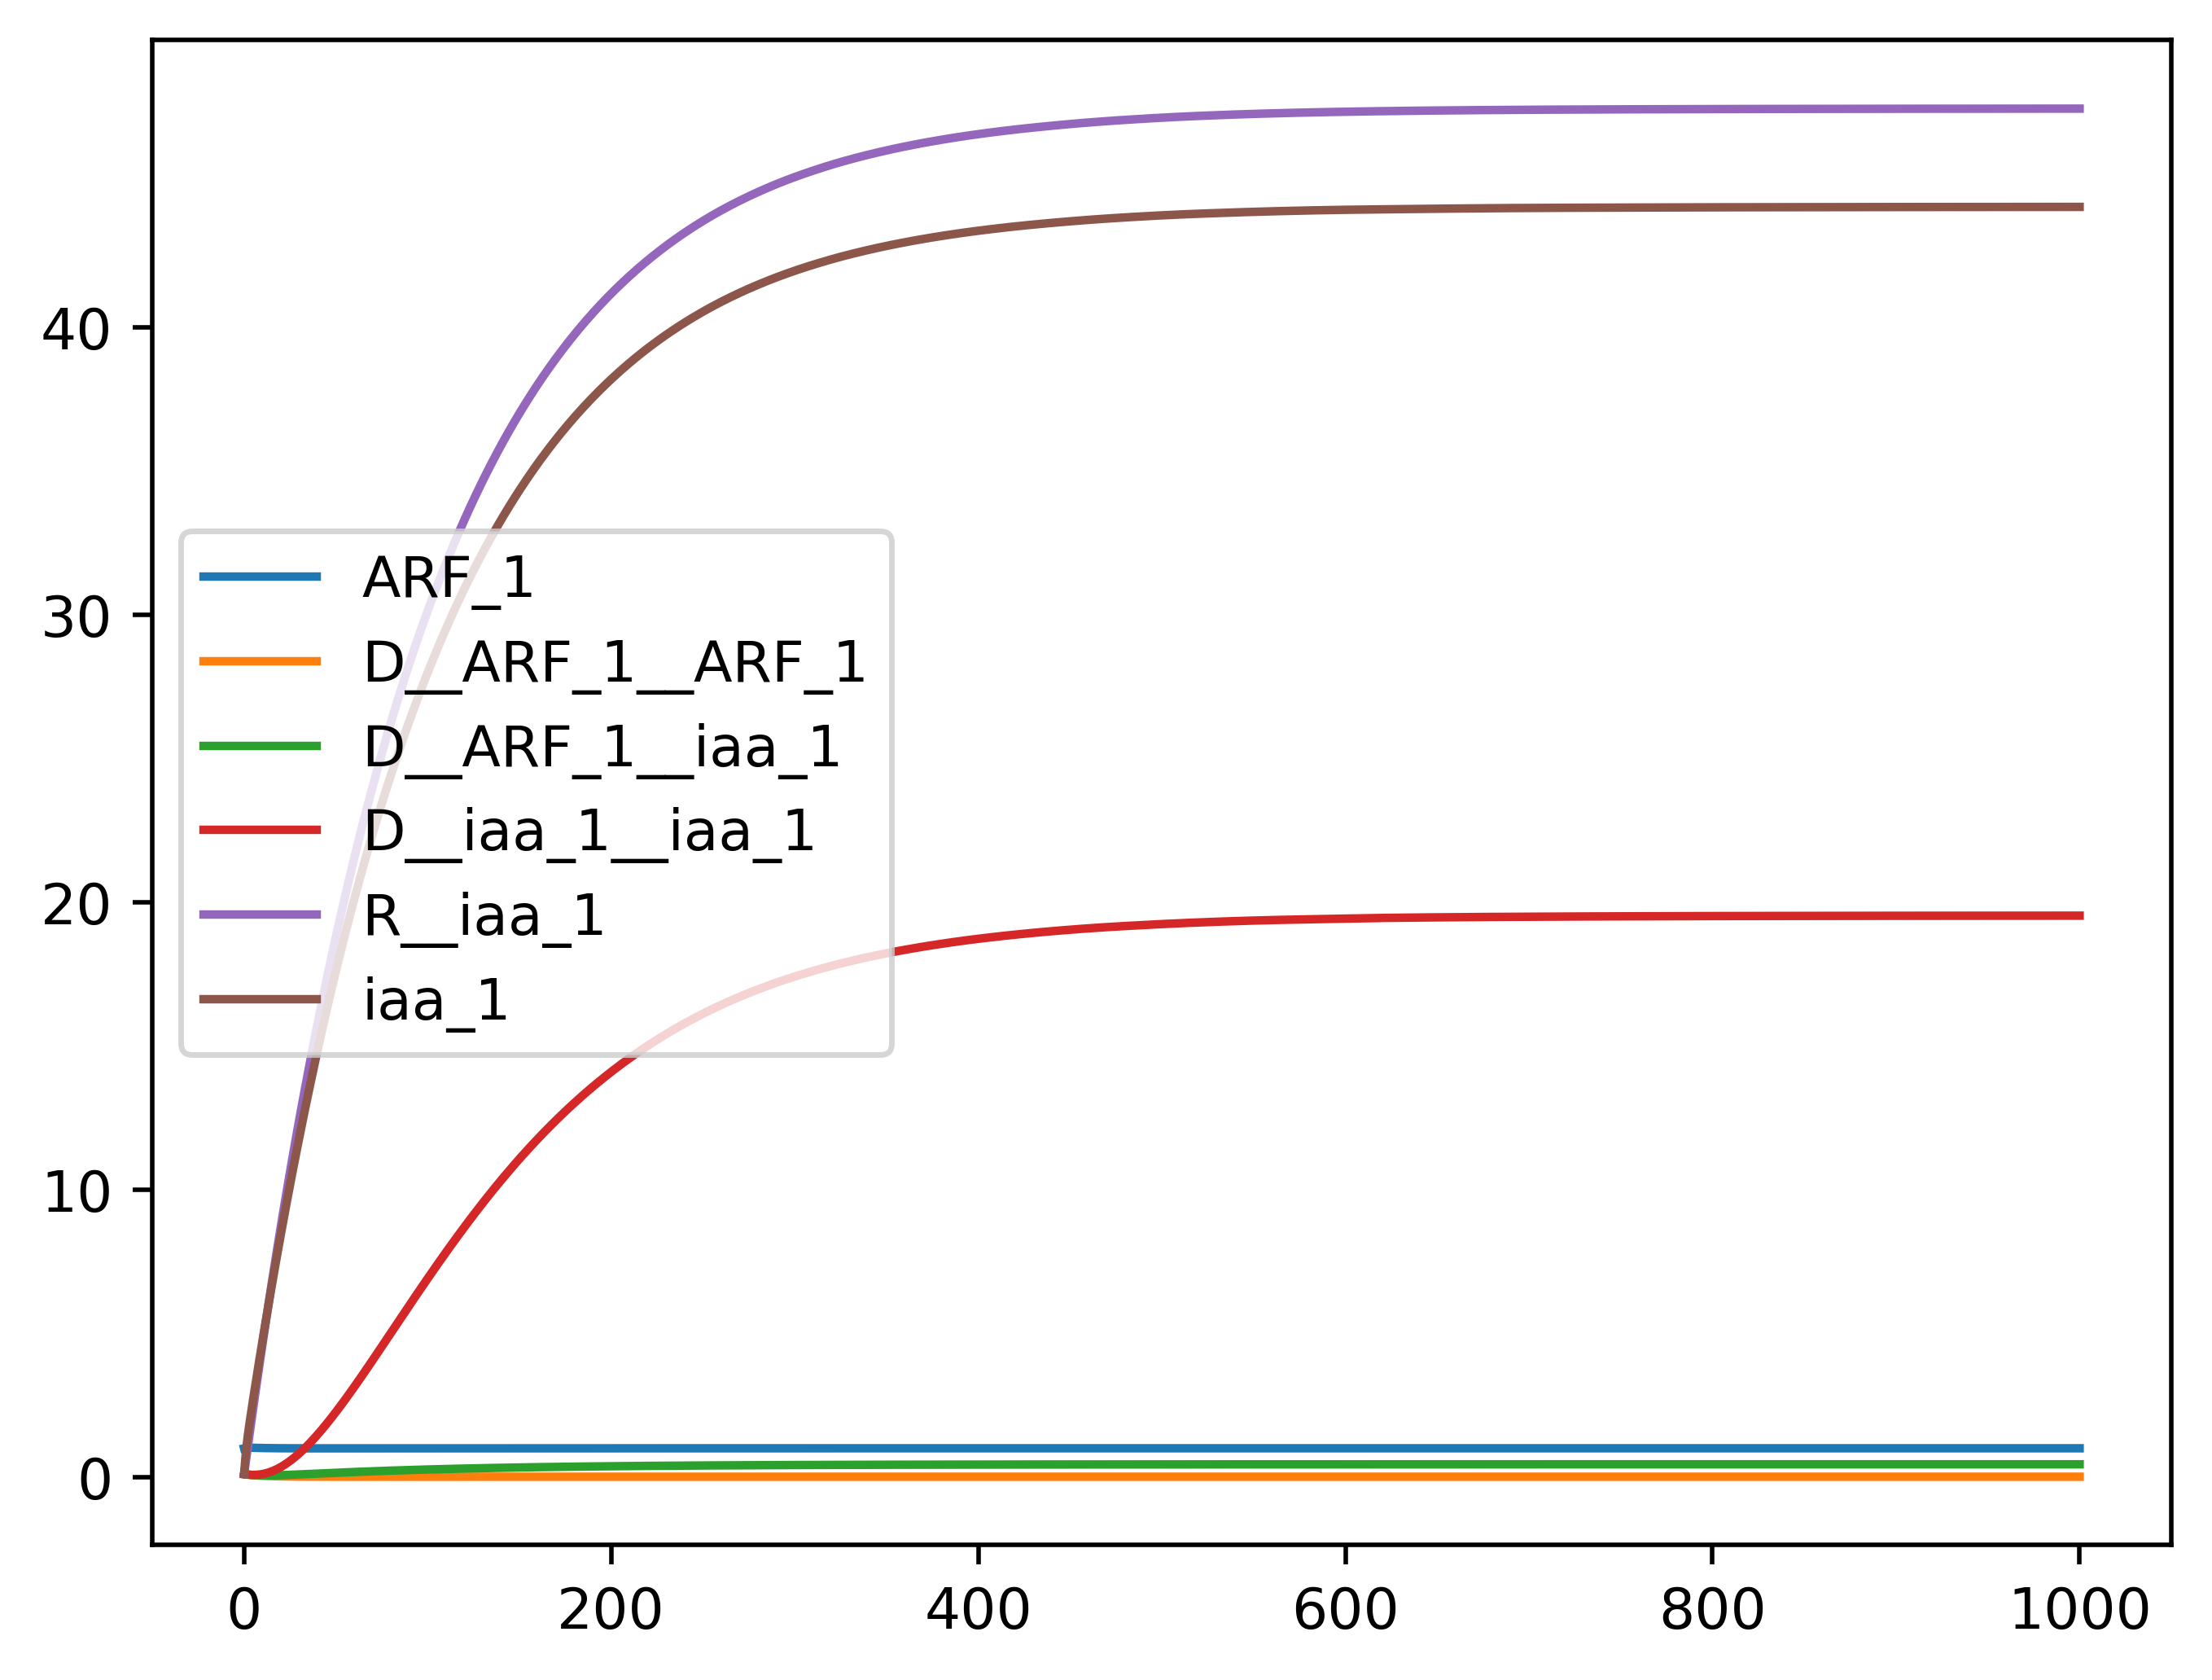

In [6]:
reduced_solver = asp_model_r.make_forward_solver()

print(full_parameter_subs_dict)

ts = np.linspace(0, 1e3, 1000)

sol1, succ = reduced_solver(ts, transition_rates, reduced_ic_dict, 1)
r_odes, free_variables, transition_rates, constraints = asp_model_r.generate_ode_system()
f_odes, free_variables, transition_rates, constraints = asp_model_full.generate_ode_system(parameter_subs_dict=full_parameter_subs_dict)

plt.plot(ts, sol1, label=reduced_ic_dict.keys())
plt.legend()

print(sp.simplify(f_odes))

dict_keys(['arf__d', 'arf__k', 'd__D__ARF_1__ARF_1', 'd__D__ARF_1__iaa_1', 'd__D__iaa_1__iaa_1', 'd__G__ARF_1', 'd__G__ARF_1__ARF_1', 'd__G__ARF_1__ARF_1__unbind__ARF_1', 'd__G__ARF_1__iaa_1', 'd__G__ARF_1__iaa_1__unbind__iaa_1', 'd__R', 'd__iaa_1_x', 'iaa__d', 'iaa__k', 'k__D__ARF_1__ARF_1', 'k__D__ARF_1__iaa_1', 'k__D__iaa_1__iaa_1', 'k__G__ARF_1', 'k__G__ARF_1__ARF_1', 'k__G__ARF_1__ARF_1__R__iaa_1', 'k__G__ARF_1__R__iaa_1', 'k__G__ARF_1__bind__ARF_1', 'k__G__ARF_1__bind__iaa_1', 'k__G__ARF_1__iaa_1', 'k__G__ARF_1__iaa_1__R__iaa_1', 'k__G__R__iaa_1', 'k__RNA__IAA', 'k__iaa_1', 'tau_G'])
{'arf__d': 1.0, 'arf__k': 1.0, 'd__D__ARF_1__ARF_1': 0.1, 'd__D__ARF_1__iaa_1': 0.1, 'd__D__iaa_1__iaa_1': 0.1, 'd__G__ARF_1': 0.01, 'd__G__ARF_1__ARF_1': 0.01, 'd__G__ARF_1__ARF_1__unbind__ARF_1': 0.0, 'd__G__ARF_1__iaa_1': 0.01, 'd__G__ARF_1__iaa_1__unbind__iaa_1': 0.0, 'd__R': 0.01, 'd__iaa_1_x': 0.1, 'iaa__d': 1.0, 'iaa__k': 1.0, 'k__D__ARF_1__ARF_1': 0.001, 'k__D__ARF_1__iaa_1': 0.001, 'k__D__ia

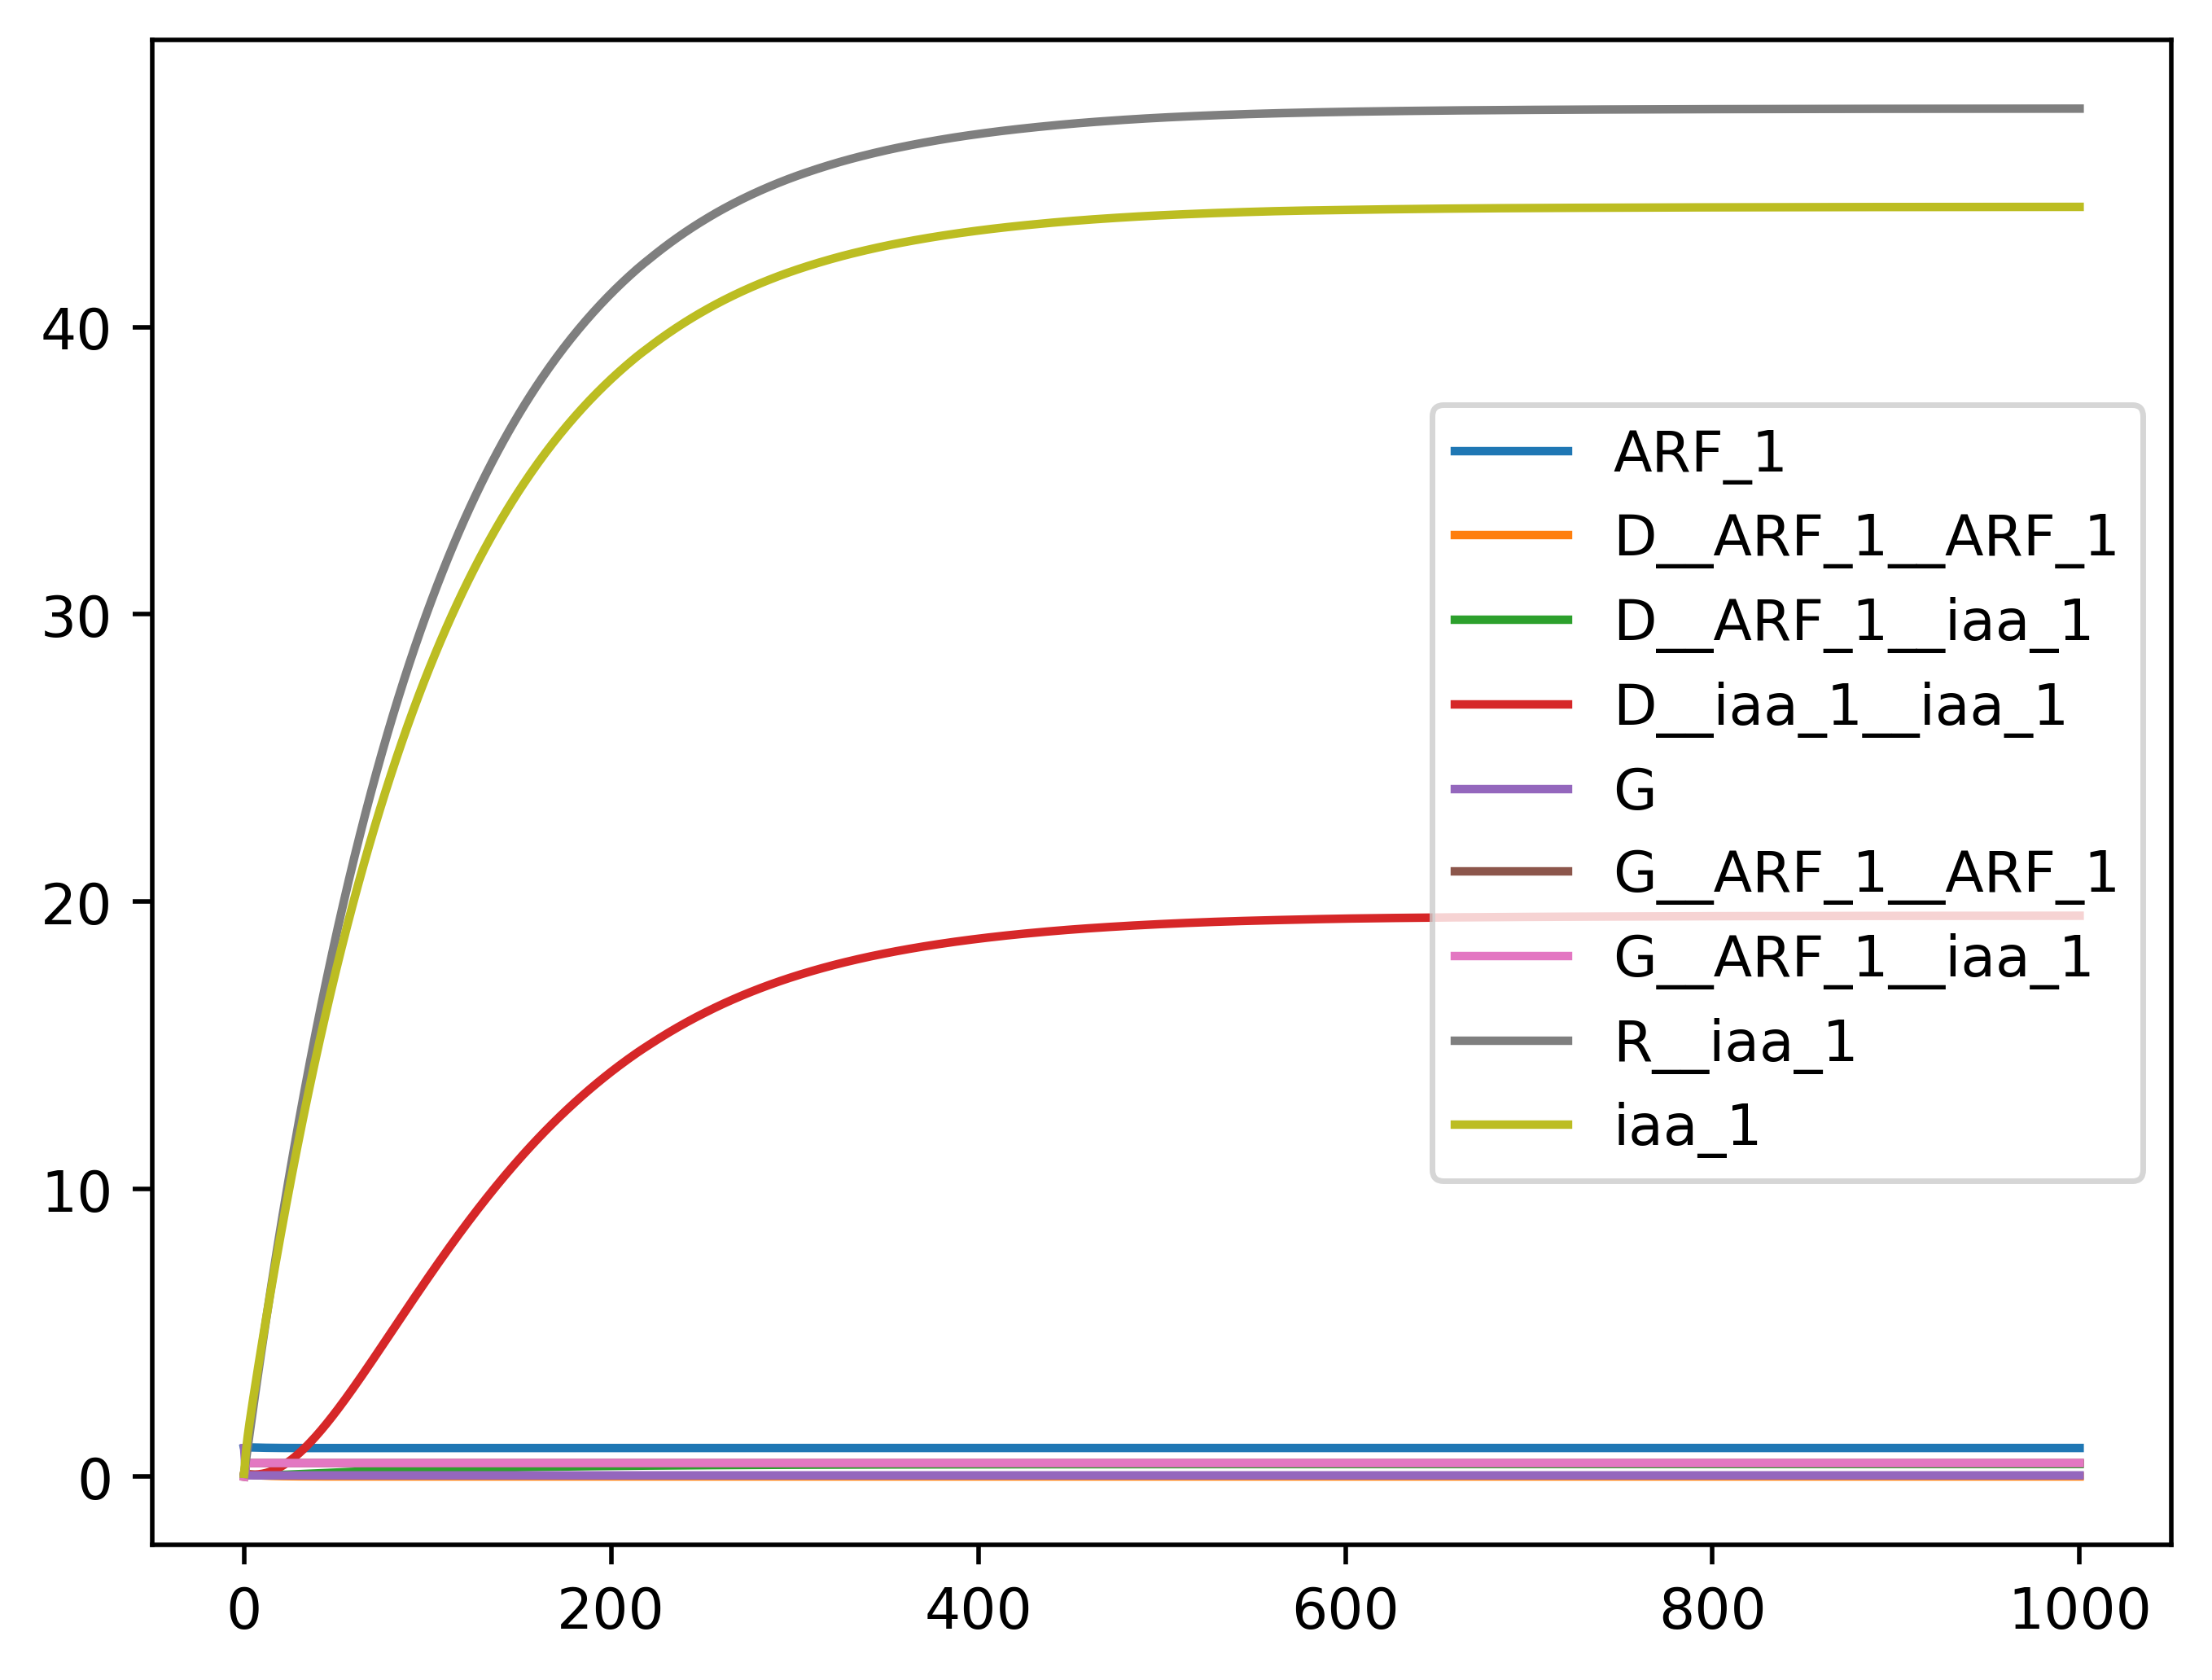

In [14]:

full_param_dict = asp_model_full.get_default_parameters(parameter_subs_dict=asp_model_r.parameter_subs_dict)

full_param_dict[promoter_timeconstant] = 1e-10

print(full_param_dict.keys())
print(asp_model_full.get_default_parameters())

full_solver = asp_model_full.make_forward_solver(parameter_subs_dict=full_parameter_subs_dict)
sol2, succ = full_solver(ts, full_param_dict, full_ic_dict, 1, strict=False)

plt.plot(ts, sol2, label=full_ic_dict.keys())
# plt.plot(ts, sol2[:, -2], label=list(full_ic_dict.keys())[-2])
plt.legend()

odes, free_variables, transition_rates, \
            _ = asp_model_r.generate_ode_system(
                                         reduced=True)

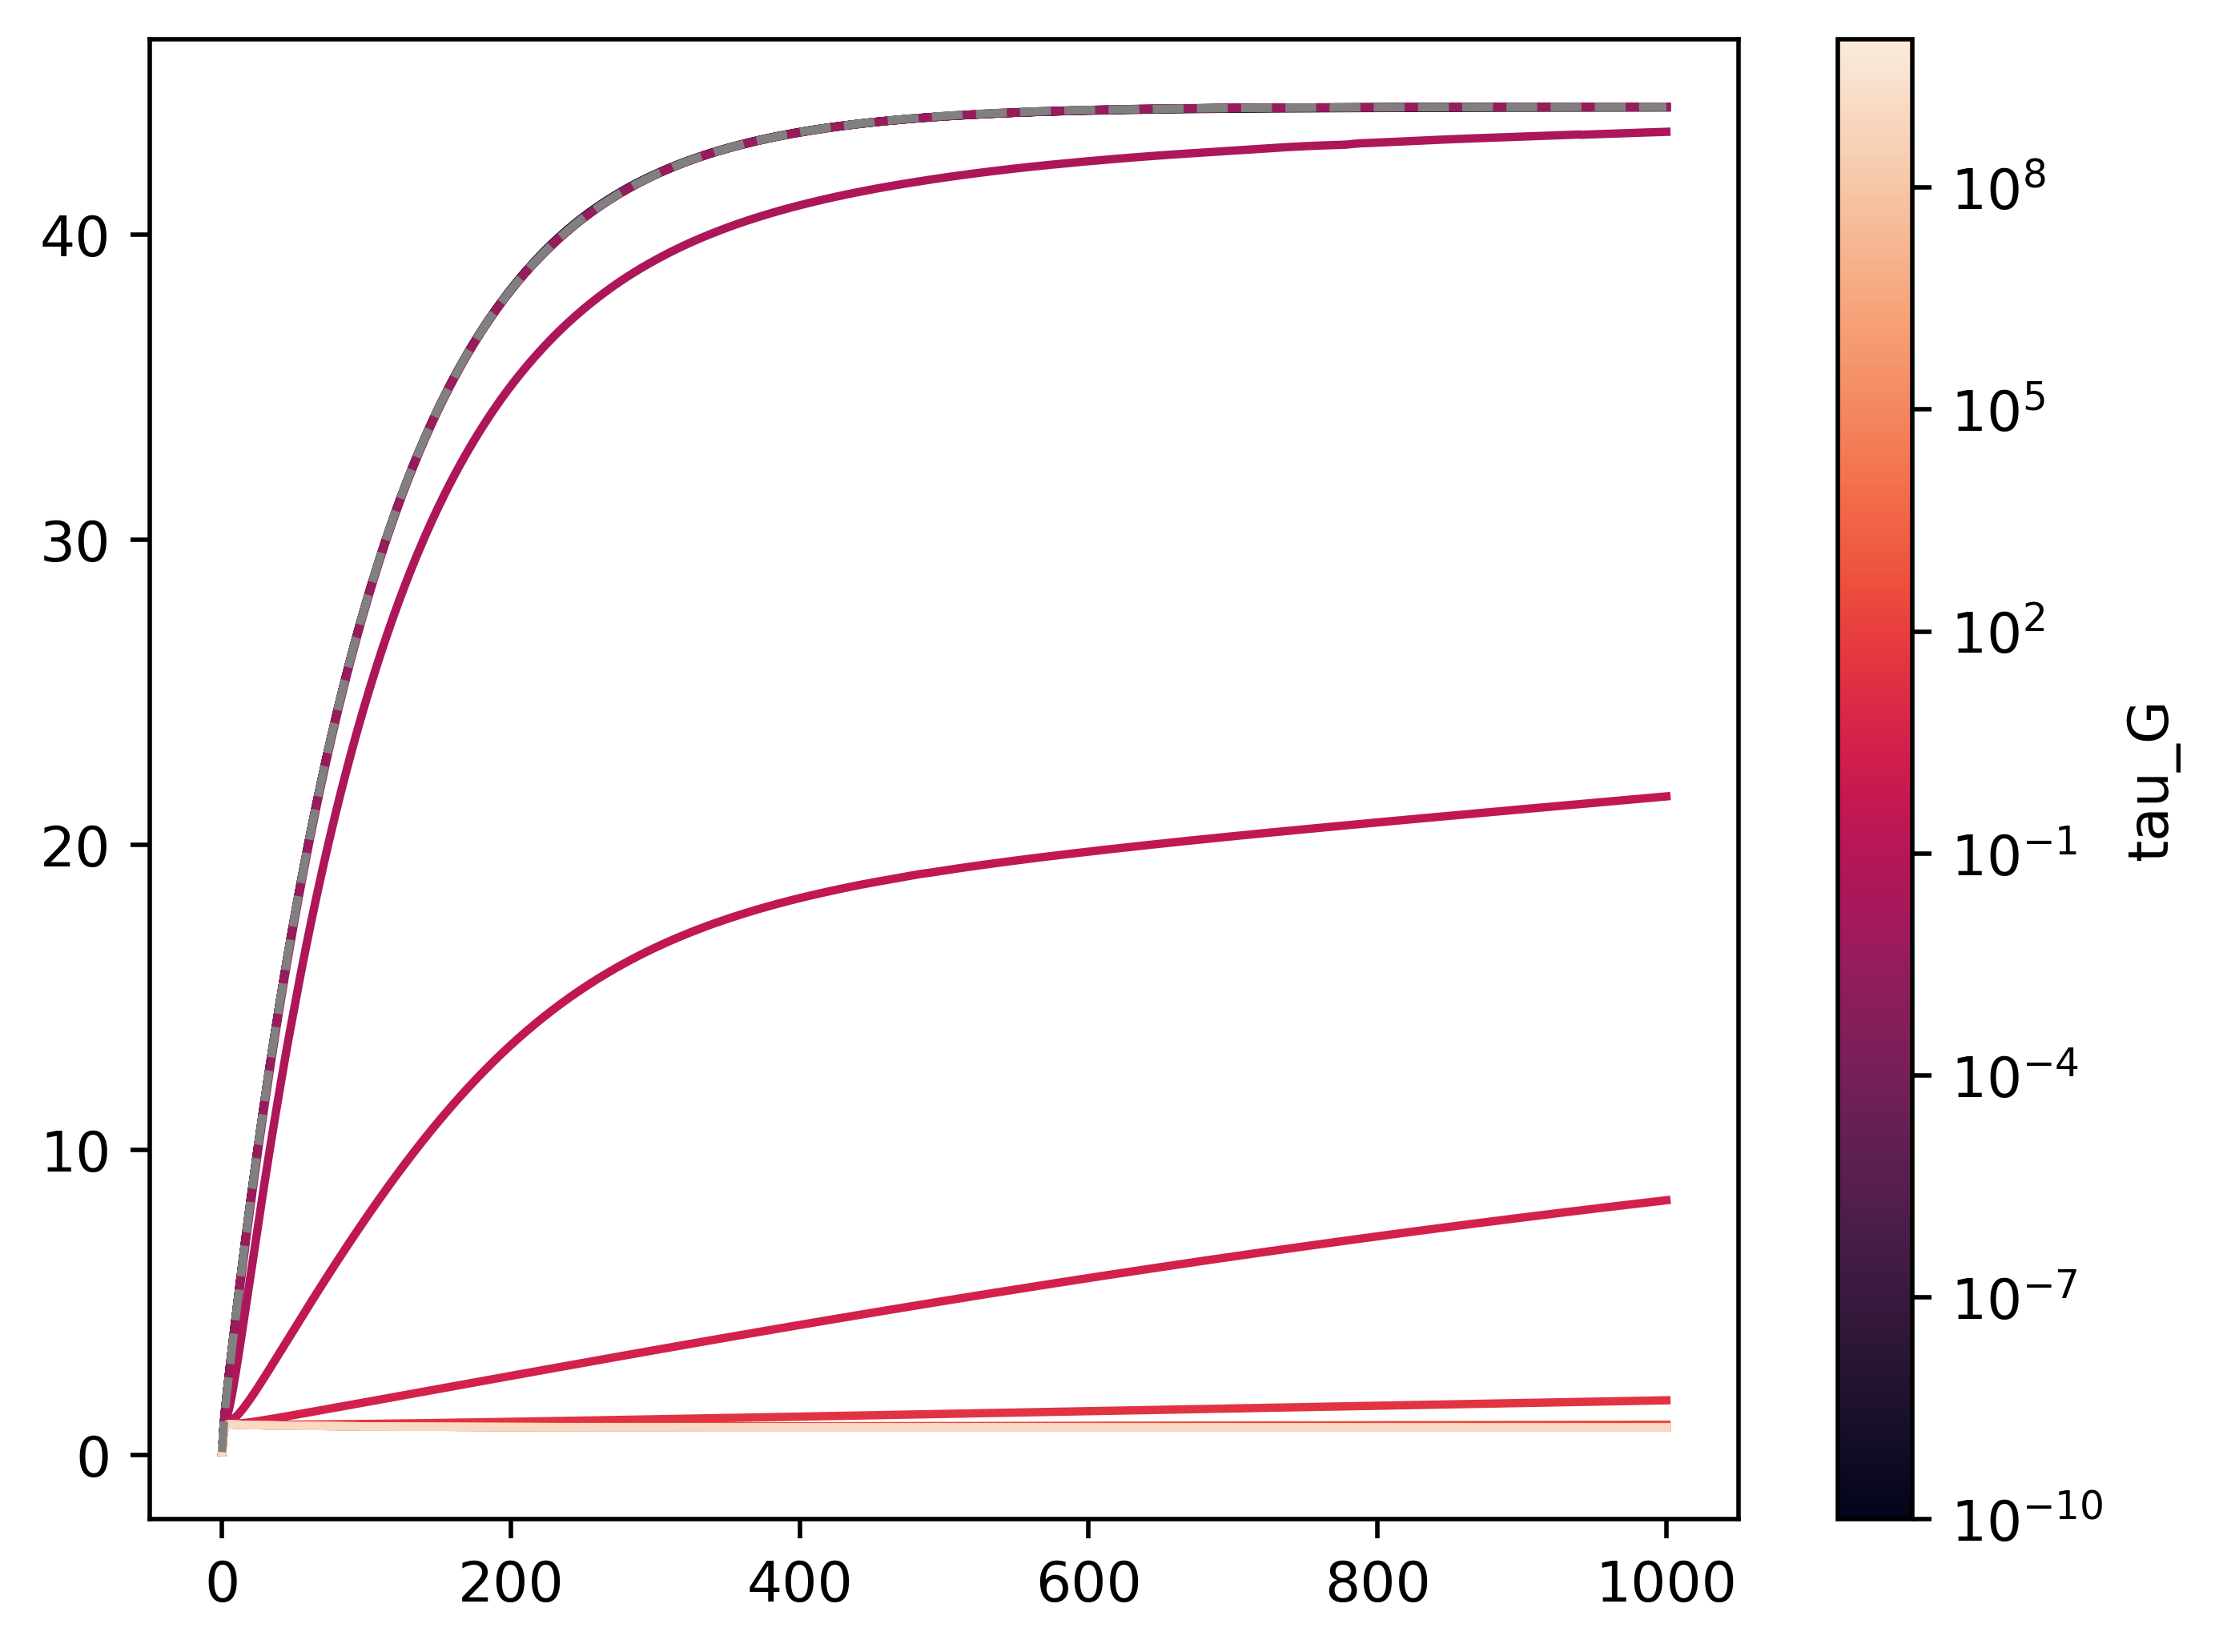

In [18]:
cmap = sns.color_palette('rocket', as_cmap=True)

plt.clf()

rmses = []
tau_vals = 10**np.linspace(-10, 10, 21)

full_param_dict = asp_model_full.get_default_parameters(parameter_subs_dict=parameter_subs_dict)

for k, v in asp_model_r.get_default_parameters().items():
    full_param_dict[k] = v

parameter_subs_dict = asp_model_r.parameter_subs_dict
for i, tau in enumerate(tau_vals):
    # full_param_dict = asp_model_full.get_default_parameters(parameter_subs_dict=parameter_subs_dict)
    full_param_dict[promoter_timeconstant] = tau
    sol2, succ = full_solver(ts, full_param_dict, full_ic_dict, 1)
    color = cmap(i / len(tau_vals)) 
    plt.plot(ts, sol2[:, -1], color=color)
    
    rmse = np.sqrt(np.mean((sol2[1:, -1] - sol1[1:, -1])**2))
    rmses.append(rmse)

plt.colorbar(mpl.cm.ScalarMappable(norm=mpl.colors.LogNorm(tau_vals[0], tau_vals[-1]), cmap='rocket'),
             orientation='vertical', label='tau_G', ax=plt.gca())
plt.plot(ts, sol1[:, -1], color='grey', ls='--')


Text(0.5, 0, 'tau_G')

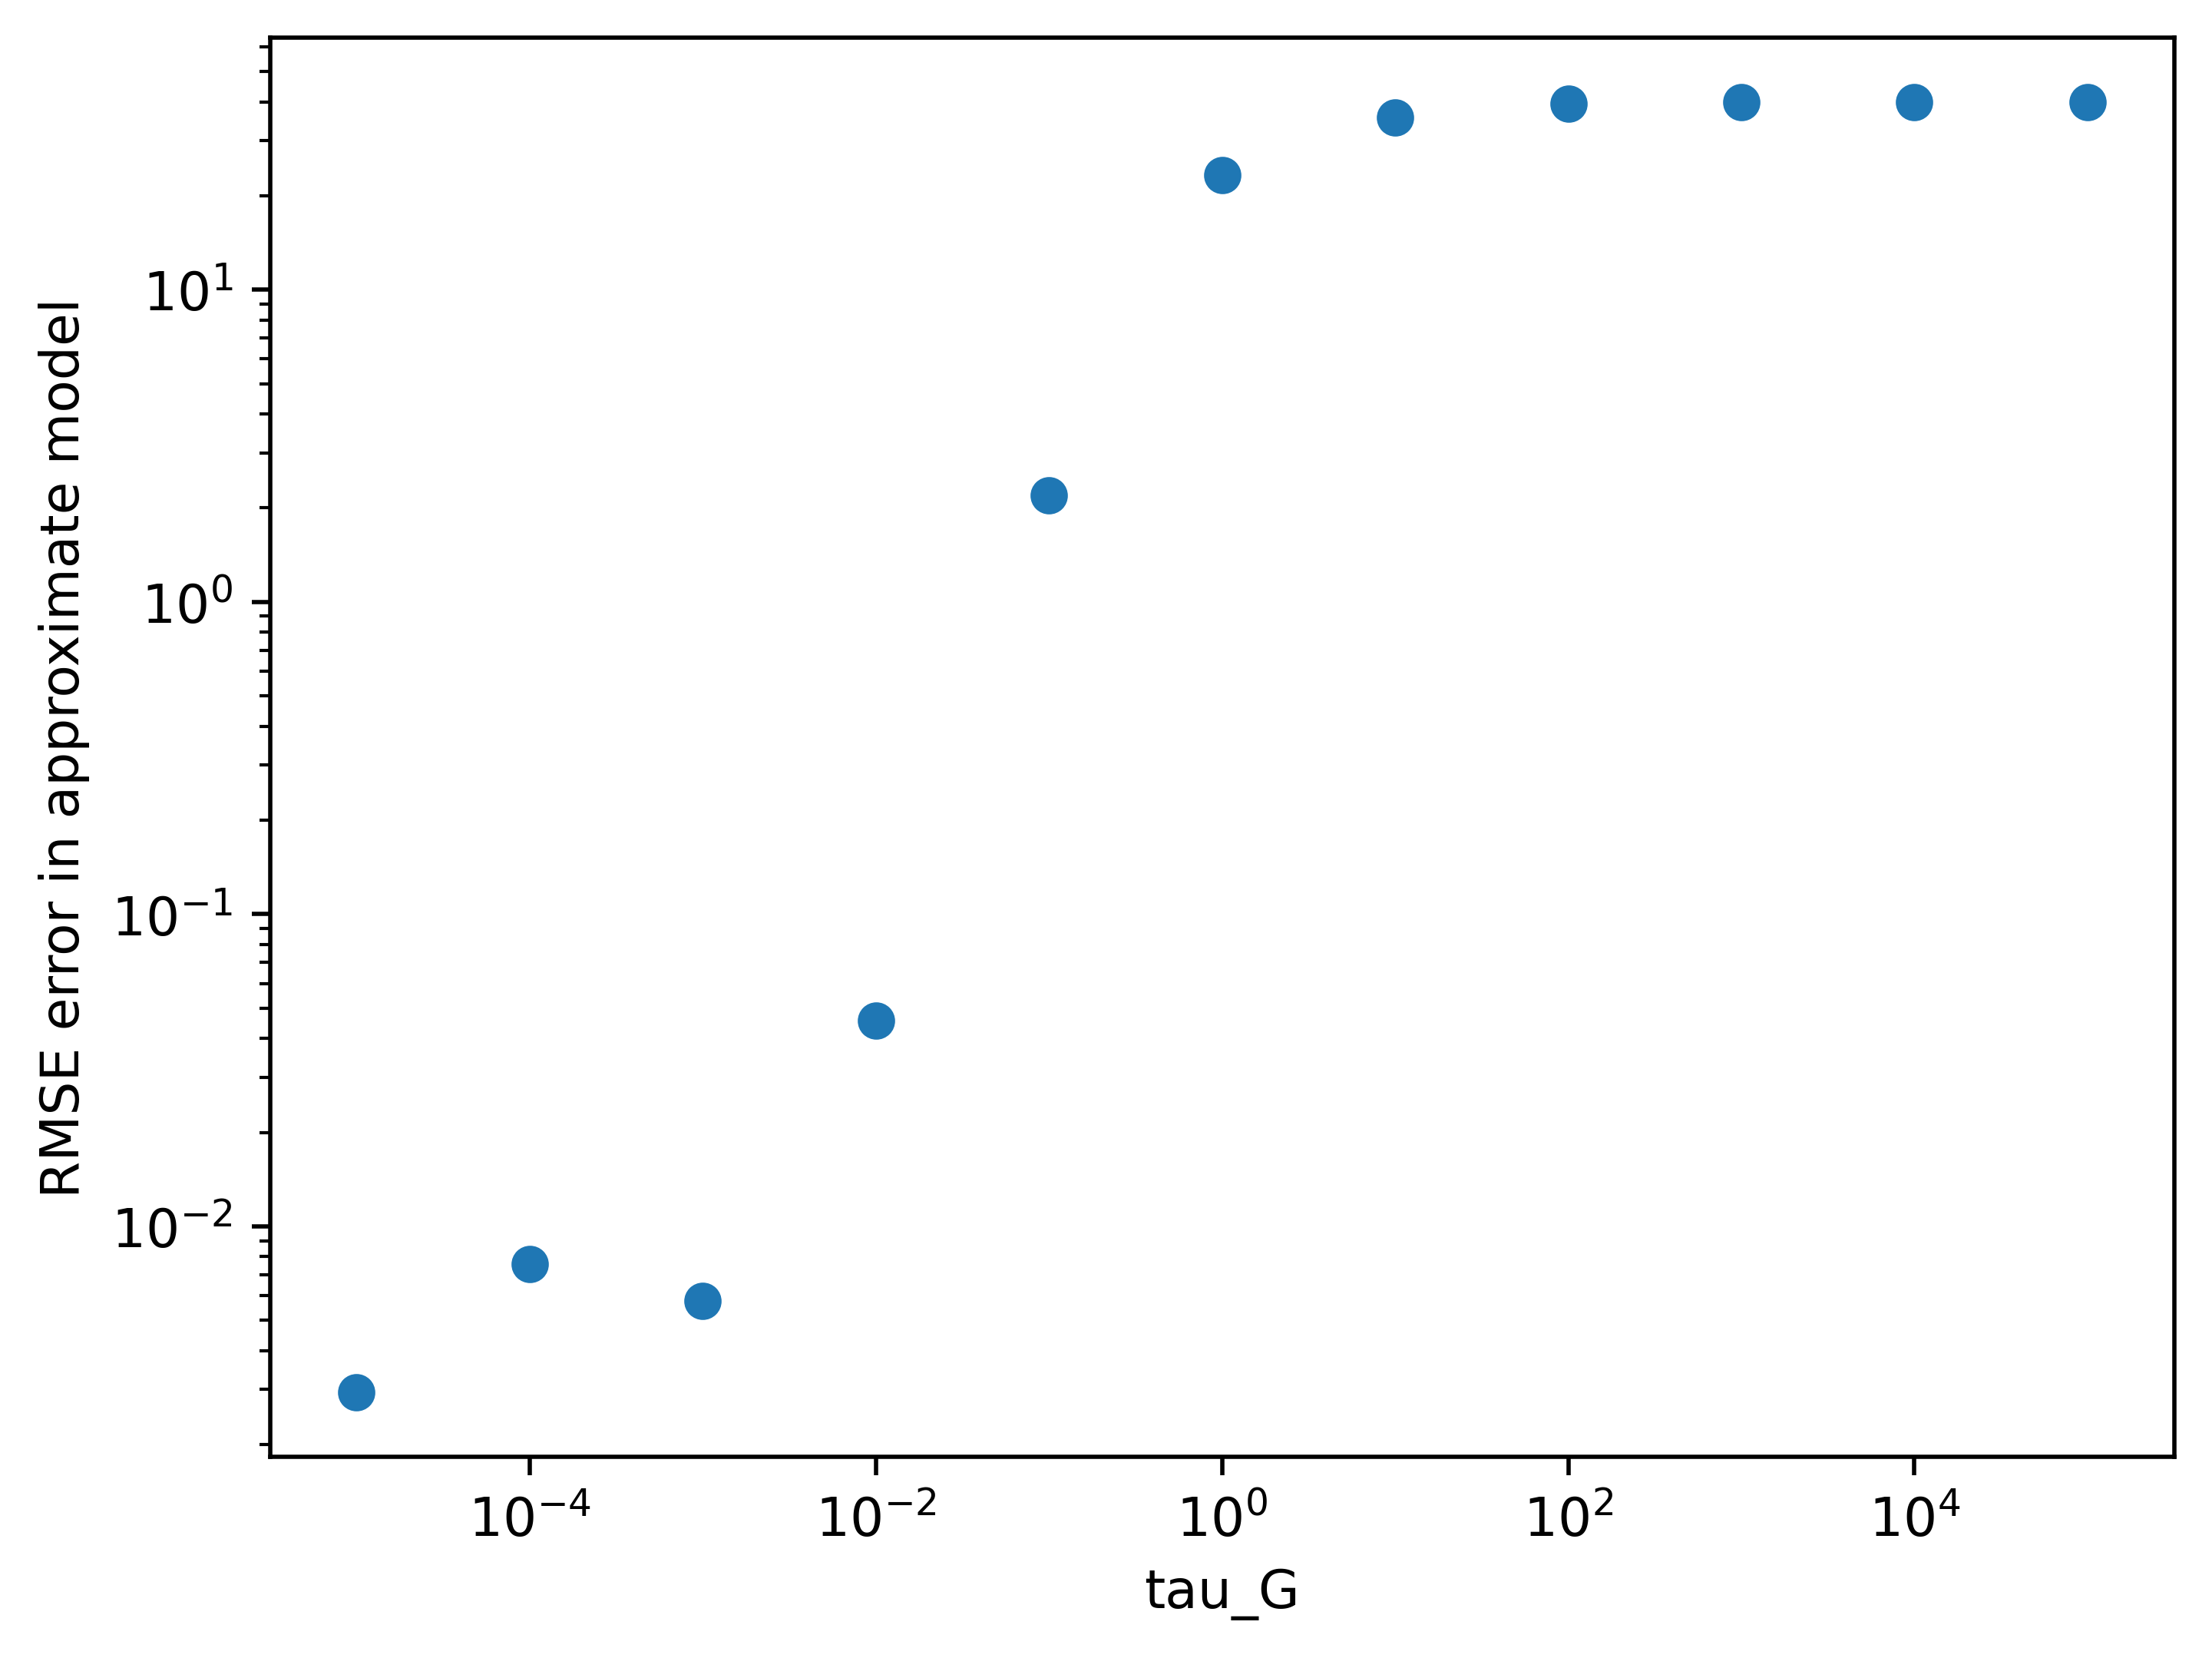

In [16]:
plt.scatter(tau_vals, rmses)
plt.xscale('log')
plt.yscale('log')
plt.ylabel("RMSE error in approximate model")
plt.xlabel("tau_G")